# Transformation report (Phase 2, task 2.10)

Built from the data store as of **2026-10-16**. For every panel variable: (1) the input as
published, (2) the real level and its seasonally adjusted version, (3) y/y growth as it enters
the y/y panel, (4) SA m/m or q/q growth as it enters the factor model's panel, with the outliers
that are set to missing marked in red.

The method is in `docs/transformations.md`; the choices for each series are in the table below.
**Exit check:** spot-check 10 series against your own numbers (the last-values table helps) and
note anything that looks wrong.

How to read the choices table:
* *real terms / weights*: `prev_year` = last year's nominal values of the series (exact);
  `same_year` = the first year of the nominal series, where this year's shares stand in;
  `fallback:` = a related nominal series; `equal` = no nominal values, every period weighs the same.
* *seasonal strength* (0-1): share of the variance of the detrended log level that is seasonal.
* *leftover seasonality p*: F-test that the SA growth rates have the same mean in every month
  (quarter); below 0.05 means seasonality is left over (X-13 with holiday effects then needs a look).


In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from nowcast.store.vintages import Store
from nowcast.transform import report
from nowcast.transform.inputs import load_inputs
from nowcast.transform.panels import build_panels

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 72
STORE = os.environ.get("NOWCAST_STORE", '../store')
AS_OF = '2026-10-16' or str(pd.Timestamp.now(tz="Asia/Tashkent").date())
inputs = load_inputs(Store(STORE), AS_OF)
panels = build_panels(inputs=inputs)
print(f"as of {AS_OF}: {panels.meta['yoy_n'].notna().sum()} variables in the y/y panel, "
      f"{panels.meta['sa_n'].notna().sum()} in the SA panel")
print("input modes:", pd.Series(panels.modes).value_counts().to_dict())

as of 2026-10-16: 63 variables in the y/y panel, 47 in the SA panel
input modes: {'vintage': 42}


## Choices for each variable

In [2]:
display(report.choices_table(panels))

,variable,freq,block,status,recipe,real terms / weights,level base,seasonal adjustment,seasonal strength,leftover seasonality p,y/y from,y/y to,SA outliers,flags
0,ind_total,M,real,core,real_growth,"prev_year 80, same_year 12",2019 nominal (own),STL robust,0.95,0.928,2019-01,2026-08,18.0,30
1,ind_mining,M,real,core,real_growth,"prev_year 80, same_year 12",2019 nominal (own),STL robust,0.89,0.759,2019-01,2026-08,5.0,17
2,ind_manuf,M,real,core,real_growth,"prev_year 80, same_year 12",2019 nominal (own),STL robust,0.96,0.975,2019-01,2026-08,5.0,17
3,ind_elec,M,real,core,real_growth,"prev_year 80, same_year 12",2019 nominal (own),STL robust,0.94,0.259,2019-01,2026-08,4.0,16
4,constr,M,real,core,real_growth,"prev_year 56, same_year 12",2021 nominal (own),STL robust,0.95,0.963,2021-01,2026-08,5.0,17
5,retail,M,real,core,real_growth,"prev_year 68, same_year 12",2020 nominal (own),STL robust,0.97,0.647,2020-01,2026-08,7.0,19
6,wholesale,M,real,core,real_growth,"prev_year 68, same_year 12",2020 nominal (own),"STL robust, 1 gaps filled for the fit only",0.76,0.932,2020-01,2026-08,9.0,23
7,mkt_trade,M,services,core,real_growth,"prev_year 20, same_year 12",,,NaN,NaN,2024-01,2026-08,NaN,12
8,mkt_ict,M,services,core,real_growth,"prev_year 20, same_year 12",,,NaN,NaN,2024-01,2026-08,NaN,12
9,mkt_transport,M,services,core,real_growth,"prev_year 20, same_year 12",,,NaN,NaN,2024-01,2026-08,NaN,12


## Flags

Every period that was treated in a special way.

In [3]:
display(report.flags_table(panels))

,variable,flag,n,periods
0,agri_output,no discrete growth: previous period missing or last year's nominal...,1,2022Q4
1,constr,outlier in SA panel (> 4 robust SD): value_clean missing,5,"2021-10, 2023-01, 2023-02, 2024-01, 2024-02"
2,constr,weights: same_year,12,"2021-01, 2021-02, 2021-03, 2021-04, 2021-05, 2021-06, 2021-07, 202..."
3,cpi,outlier in SA panel (> 4 robust SD): value_clean missing,6,"2017-07, 2017-12, 2018-01, 2018-11, 2019-08, 2024-05"
4,exports_gold,outlier in SA panel (> 4 robust SD): value_clean missing,7,"2024-01, 2024-02, 2024-03, 2024-08, 2024-12, 2025-01, 2025-02"
5,exports_nogold,outlier in SA panel (> 4 robust SD): value_clean missing,8,"2024-02, 2024-06, 2024-07, 2024-09, 2024-10, 2024-11, 2024-12, 202..."
6,exports_total,outlier in SA panel (> 4 robust SD): value_clean missing,6,"2022-03, 2022-06, 2023-02, 2023-03, 2026-02, 2026-04"
7,freight,weights: equal,10,"2024Q1, 2024Q2, 2024Q3, 2024Q4, 2025Q1, 2025Q2, 2025Q3, 2025Q4 ..."
8,gdp,outlier in SA panel (> 4 robust SD): value_clean missing,2,"2020Q2, 2020Q4"
9,gva,outlier in SA panel (> 4 robust SD): value_clean missing,2,"2020Q2, 2020Q4"


## Last six y/y values (for the spot check)

In [4]:
display(report.last_values(panels))

,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
ind_total,8.41,7.26,8.24,8.33,7.34,8.68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ind_mining,-3.80,14.21,5.91,-15.96,-11.80,-18.18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ind_manuf,10.81,6.96,8.93,9.44,10.13,9.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ind_elec,-0.14,4.03,5.52,23.30,9.19,37.60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
constr,20.87,11.23,16.11,12.45,7.94,4.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retail,39.15,16.52,13.71,17.71,20.20,11.98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wholesale,0.91,17.43,25.62,19.75,11.41,34.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mkt_trade,19.18,0.87,14.26,19.67,16.82,46.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mkt_ict,15.78,40.11,21.84,21.81,10.24,29.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mkt_transport,23.15,20.12,7.45,21.70,11.98,26.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Monthly variables

### `ind_total`

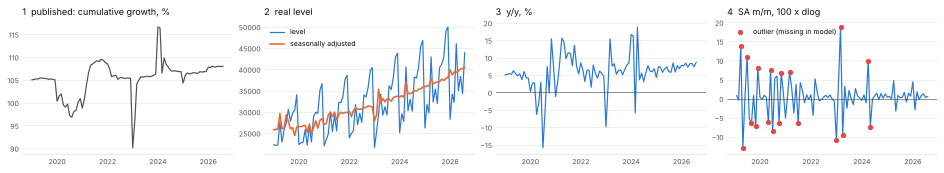

In [5]:
fig = report.figure(panels, inputs, 'ind_total')
plt.show()

### `ind_mining`

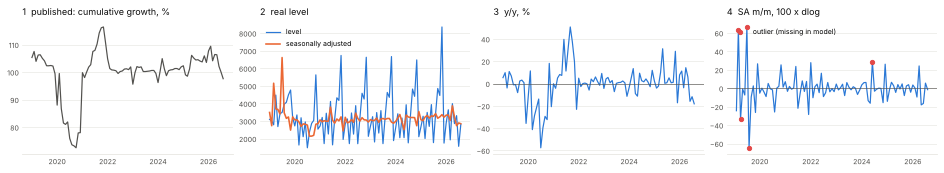

In [6]:
fig = report.figure(panels, inputs, 'ind_mining')
plt.show()

### `ind_manuf`

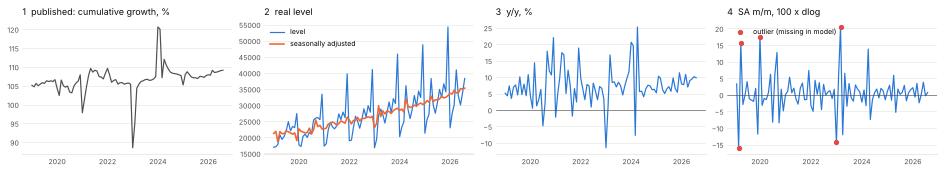

In [7]:
fig = report.figure(panels, inputs, 'ind_manuf')
plt.show()

### `ind_elec`

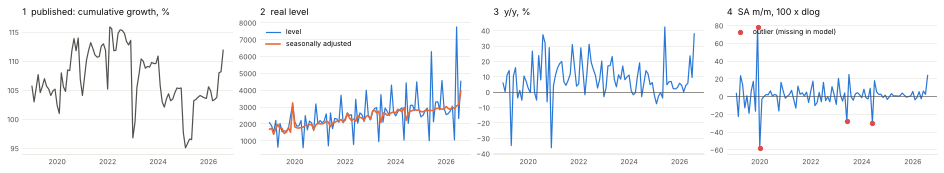

In [8]:
fig = report.figure(panels, inputs, 'ind_elec')
plt.show()

### `constr`

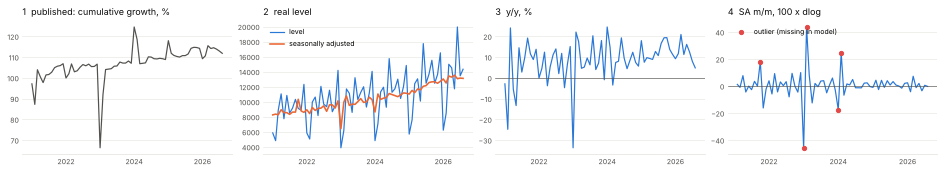

In [9]:
fig = report.figure(panels, inputs, 'constr')
plt.show()

### `retail`

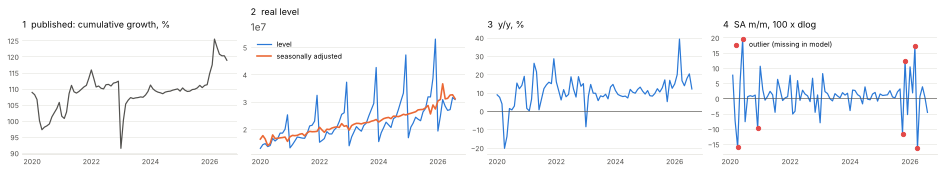

In [10]:
fig = report.figure(panels, inputs, 'retail')
plt.show()

### `wholesale`

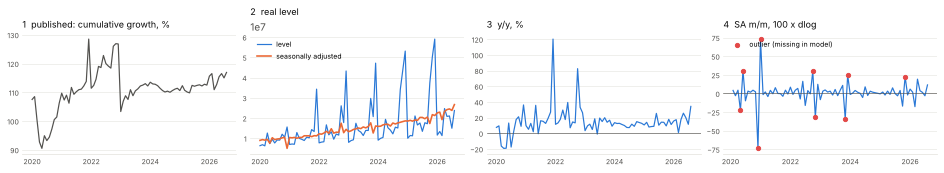

In [11]:
fig = report.figure(panels, inputs, 'wholesale')
plt.show()

### `mkt_trade`

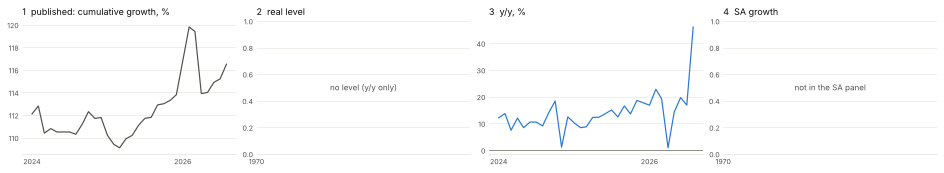

In [12]:
fig = report.figure(panels, inputs, 'mkt_trade')
plt.show()

### `mkt_ict`

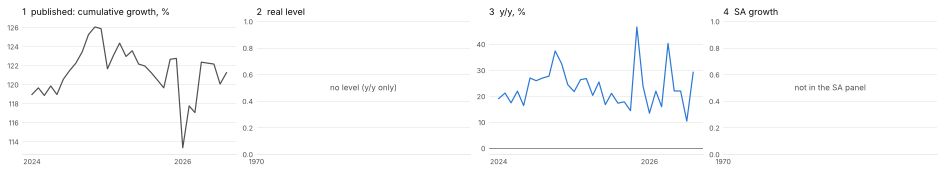

In [13]:
fig = report.figure(panels, inputs, 'mkt_ict')
plt.show()

### `mkt_transport`

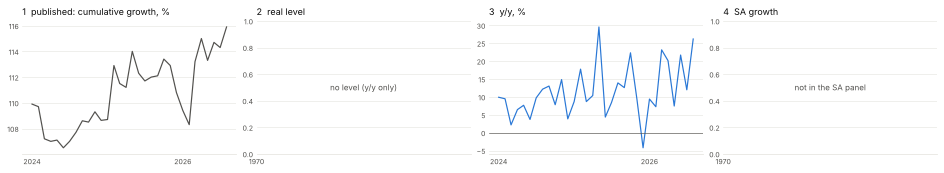

In [14]:
fig = report.figure(panels, inputs, 'mkt_transport')
plt.show()

### `mkt_motor_transport`

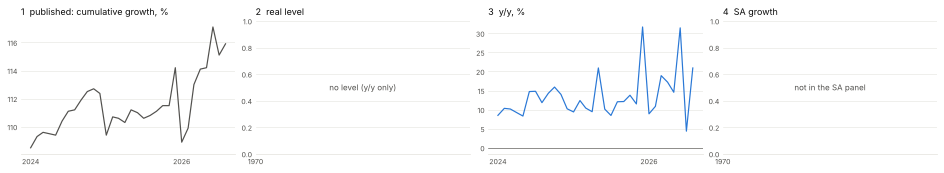

In [15]:
fig = report.figure(panels, inputs, 'mkt_motor_transport')
plt.show()

### `mkt_accommodation`

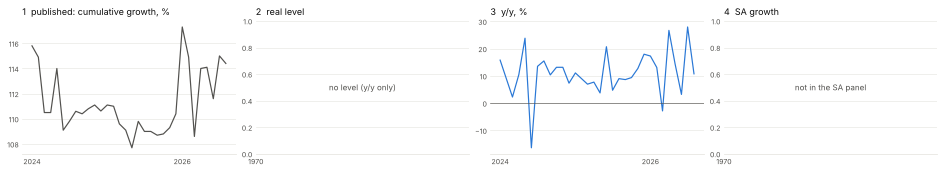

In [16]:
fig = report.figure(panels, inputs, 'mkt_accommodation')
plt.show()

### `mkt_finance`

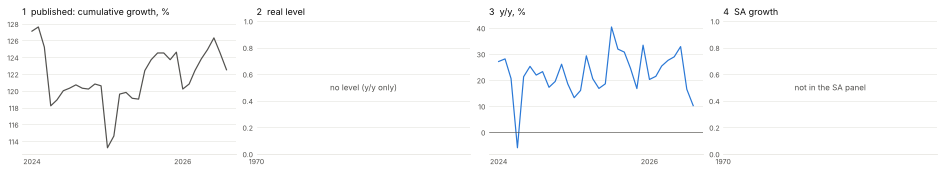

In [17]:
fig = report.figure(panels, inputs, 'mkt_finance')
plt.show()

### `mkt_real_estate`

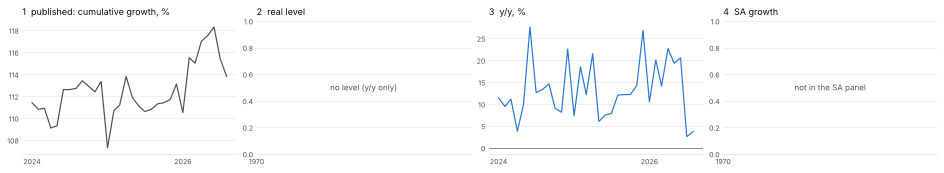

In [18]:
fig = report.figure(panels, inputs, 'mkt_real_estate')
plt.show()

### `mkt_engineering`

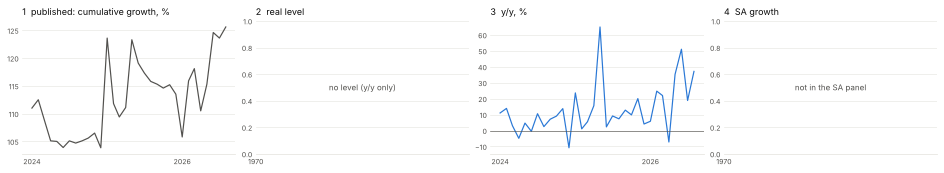

In [19]:
fig = report.figure(panels, inputs, 'mkt_engineering')
plt.show()

### `mkt_renting`

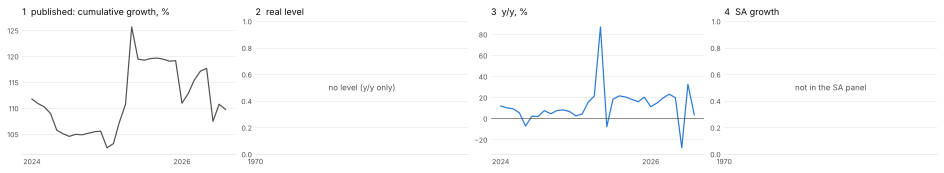

In [20]:
fig = report.figure(panels, inputs, 'mkt_renting')
plt.show()

### `mkt_education`

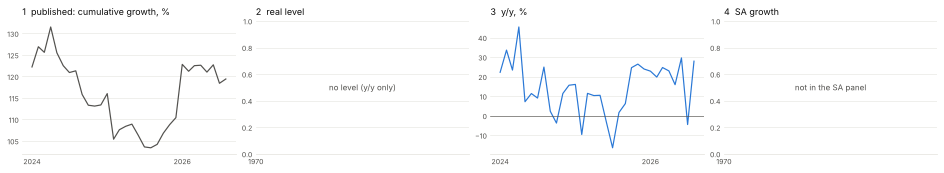

In [21]:
fig = report.figure(panels, inputs, 'mkt_education')
plt.show()

### `mkt_health`

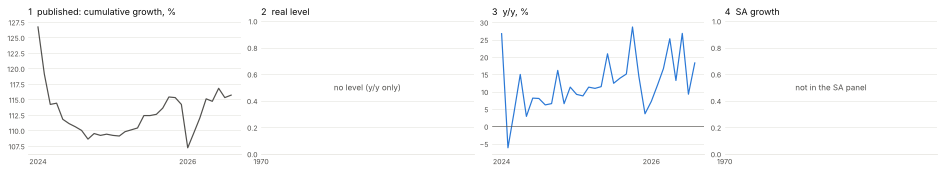

In [22]:
fig = report.figure(panels, inputs, 'mkt_health')
plt.show()

### `mkt_repair`

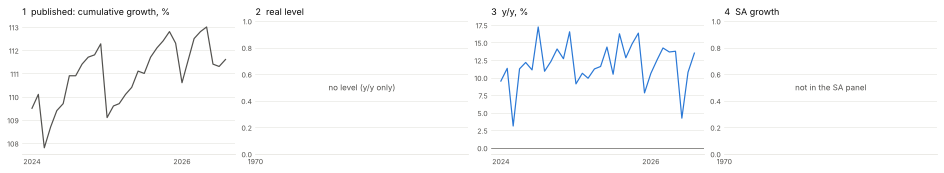

In [23]:
fig = report.figure(panels, inputs, 'mkt_repair')
plt.show()

### `mkt_personal`

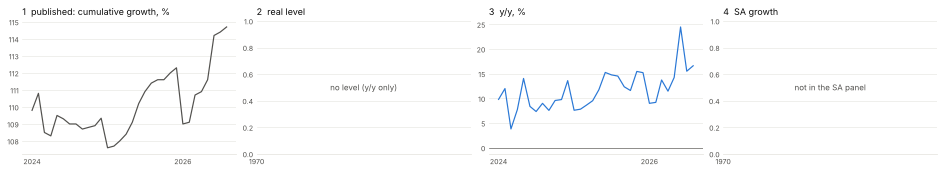

In [24]:
fig = report.figure(panels, inputs, 'mkt_personal')
plt.show()

### `mkt_other`

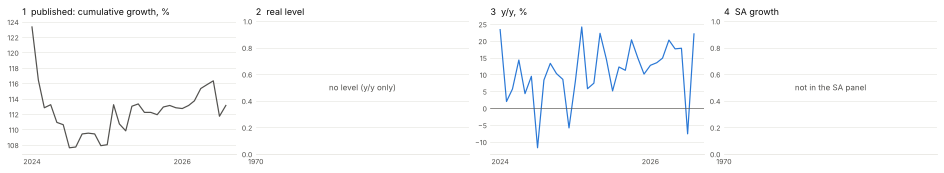

In [25]:
fig = report.figure(panels, inputs, 'mkt_other')
plt.show()

### `exports_nogold`

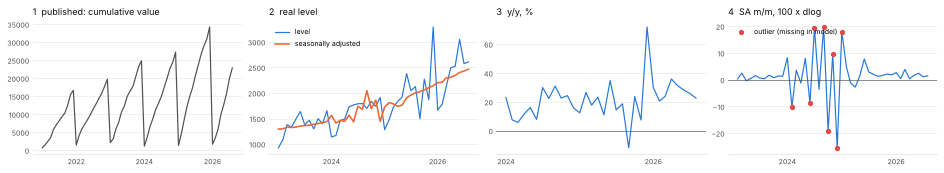

In [26]:
fig = report.figure(panels, inputs, 'exports_nogold')
plt.show()

### `exports_gold`

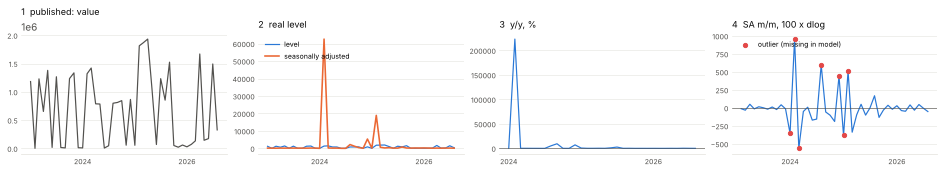

In [27]:
fig = report.figure(panels, inputs, 'exports_gold')
plt.show()

### `exports_total`

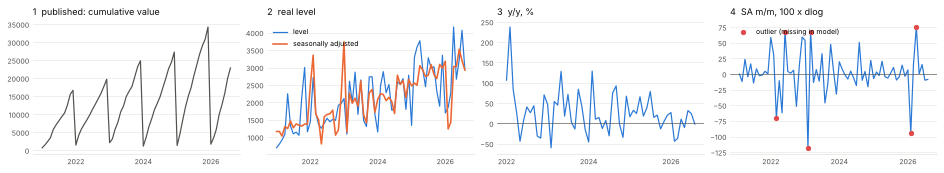

In [28]:
fig = report.figure(panels, inputs, 'exports_total')
plt.show()

### `imports`

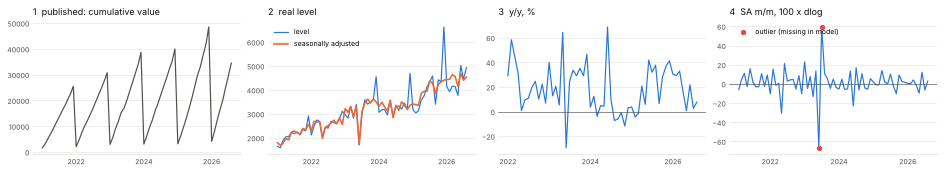

In [29]:
fig = report.figure(panels, inputs, 'imports')
plt.show()

### `usd_rate`

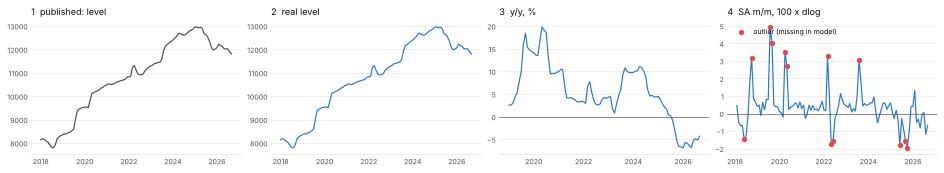

In [30]:
fig = report.figure(panels, inputs, 'usd_rate')
plt.show()

### `cpi`

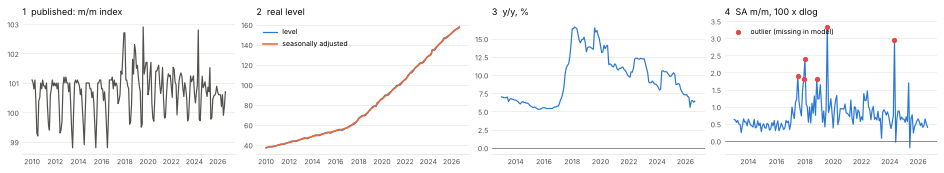

In [31]:
fig = report.figure(panels, inputs, 'cpi')
plt.show()

### `ppi`

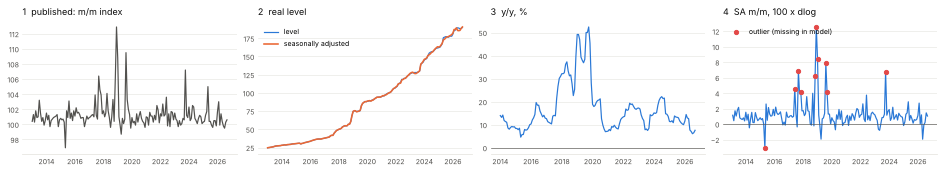

In [32]:
fig = report.figure(panels, inputs, 'ppi')
plt.show()

### `m2_real`

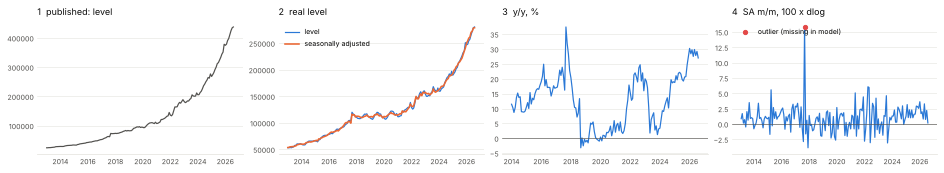

In [33]:
fig = report.figure(panels, inputs, 'm2_real')
plt.show()

### `reserves_fx`

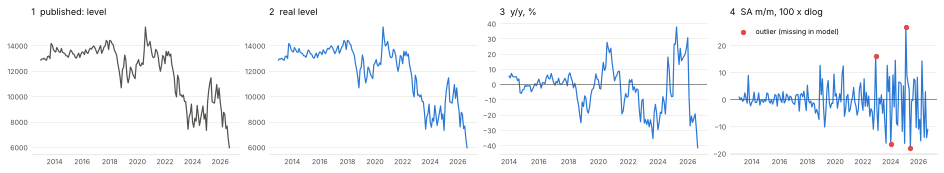

In [34]:
fig = report.figure(panels, inputs, 'reserves_fx')
plt.show()

### `reserves_gold`

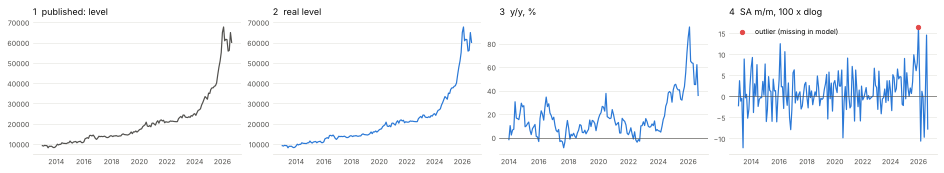

In [35]:
fig = report.figure(panels, inputs, 'reserves_gold')
plt.show()

### `gold_price`

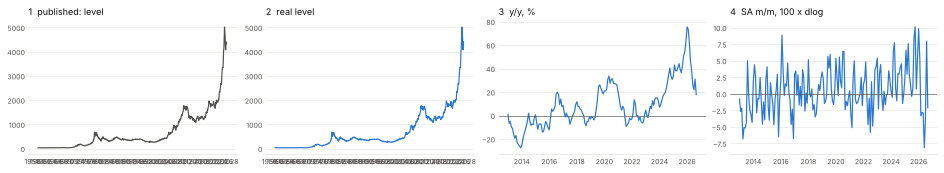

In [36]:
fig = report.figure(panels, inputs, 'gold_price')
plt.show()

### `rate_deposit_hh`

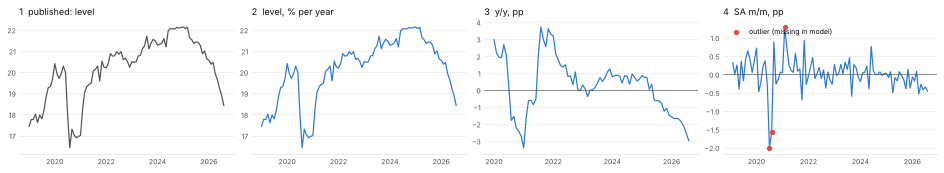

In [37]:
fig = report.figure(panels, inputs, 'rate_deposit_hh')
plt.show()

### `rate_deposit_firms`

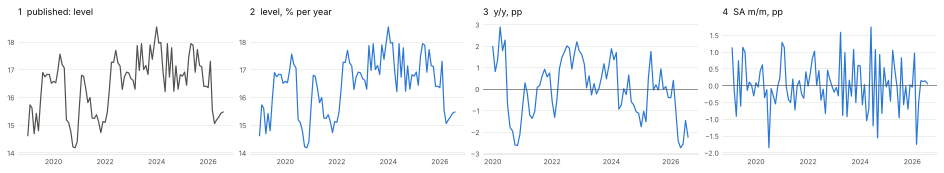

In [38]:
fig = report.figure(panels, inputs, 'rate_deposit_firms')
plt.show()

### `rate_loan_hh`

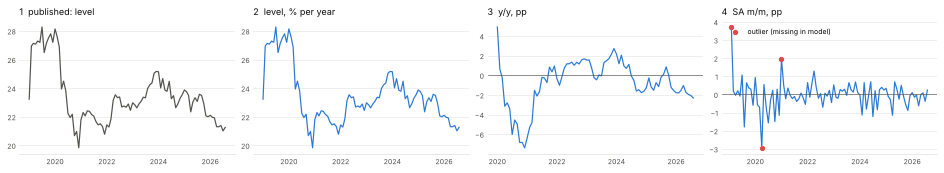

In [39]:
fig = report.figure(panels, inputs, 'rate_loan_hh')
plt.show()

### `rate_loan_firms`

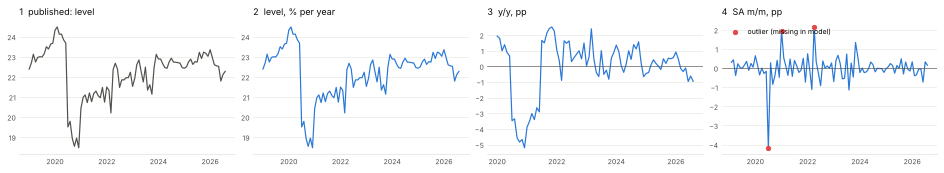

In [40]:
fig = report.figure(panels, inputs, 'rate_loan_firms')
plt.show()

### `policy_rate`

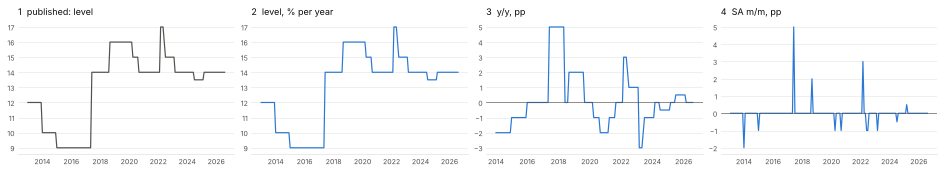

In [41]:
fig = report.figure(panels, inputs, 'policy_rate')
plt.show()

### `new_small_business`

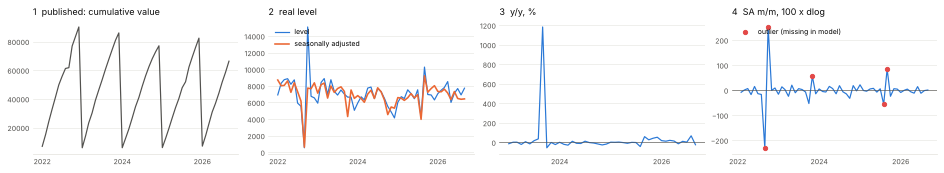

In [42]:
fig = report.figure(panels, inputs, 'new_small_business')
plt.show()

### `operating_enterprises`

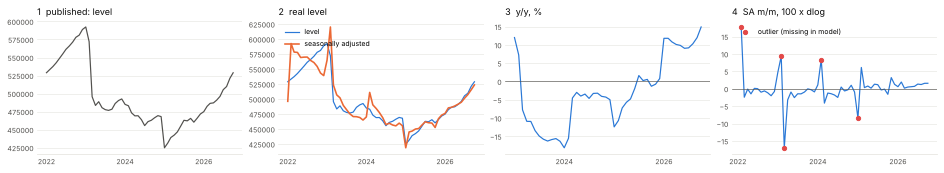

In [43]:
fig = report.figure(panels, inputs, 'operating_enterprises')
plt.show()

## Quarterly variables

### `gdp`

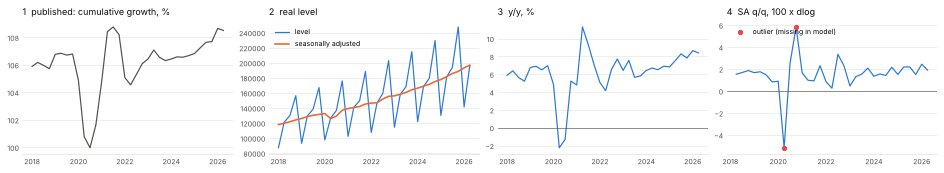

In [44]:
fig = report.figure(panels, inputs, 'gdp')
plt.show()

### `gva`

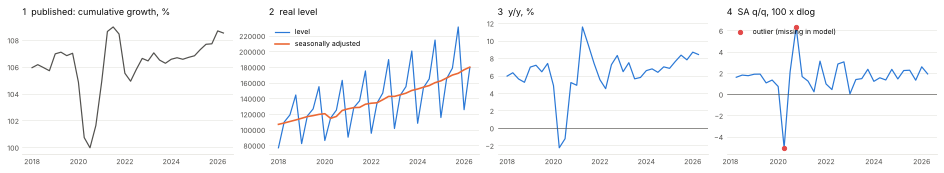

In [45]:
fig = report.figure(panels, inputs, 'gva')
plt.show()

### `gva_agriculture`

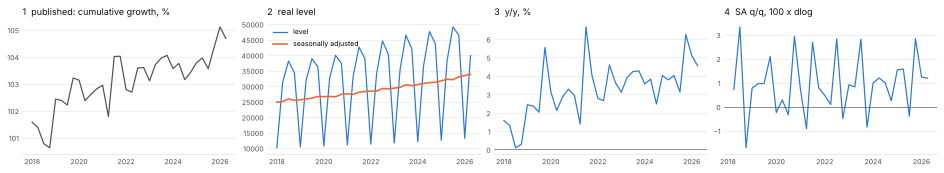

In [46]:
fig = report.figure(panels, inputs, 'gva_agriculture')
plt.show()

### `gva_industry`

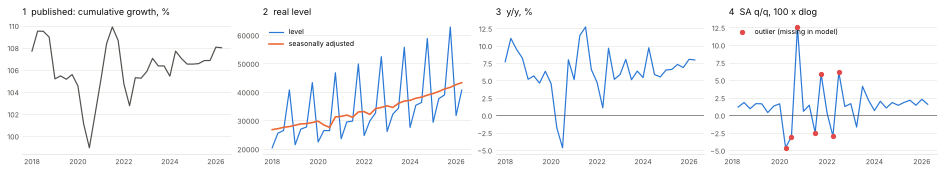

In [47]:
fig = report.figure(panels, inputs, 'gva_industry')
plt.show()

### `gva_mining`

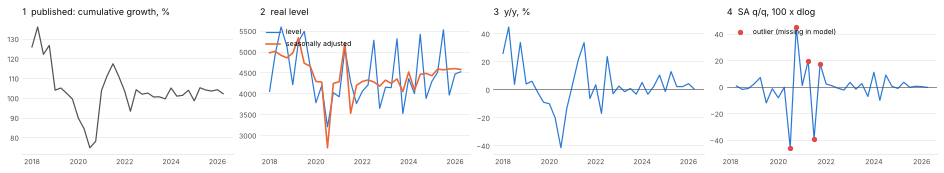

In [48]:
fig = report.figure(panels, inputs, 'gva_mining')
plt.show()

### `gva_manufacturing`

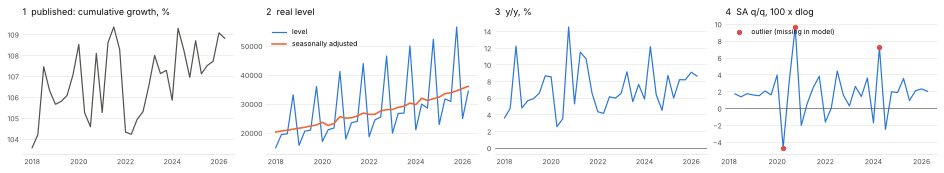

In [49]:
fig = report.figure(panels, inputs, 'gva_manufacturing')
plt.show()

### `gva_electricity`

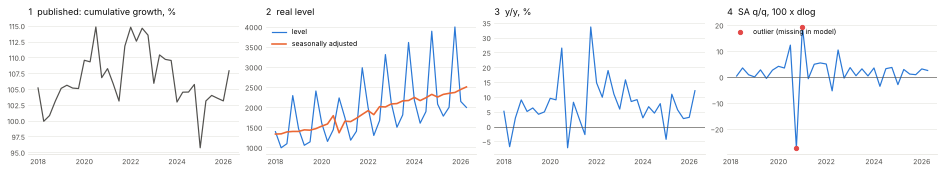

In [50]:
fig = report.figure(panels, inputs, 'gva_electricity')
plt.show()

### `gva_water`

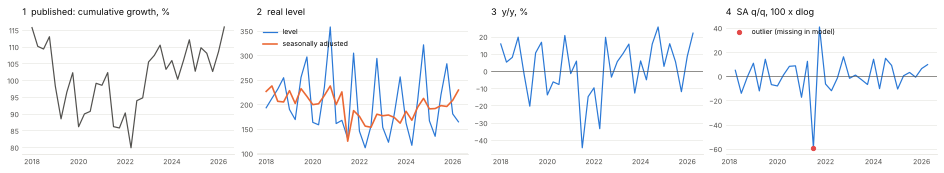

In [51]:
fig = report.figure(panels, inputs, 'gva_water')
plt.show()

### `gva_construction`

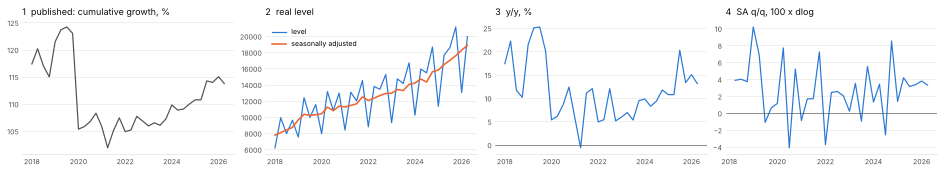

In [52]:
fig = report.figure(panels, inputs, 'gva_construction')
plt.show()

### `gva_trade_accommodation`

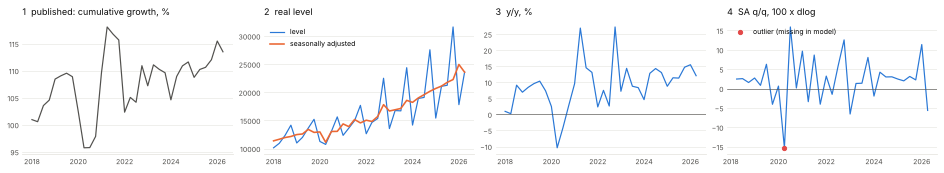

In [53]:
fig = report.figure(panels, inputs, 'gva_trade_accommodation')
plt.show()

### `gva_trade`

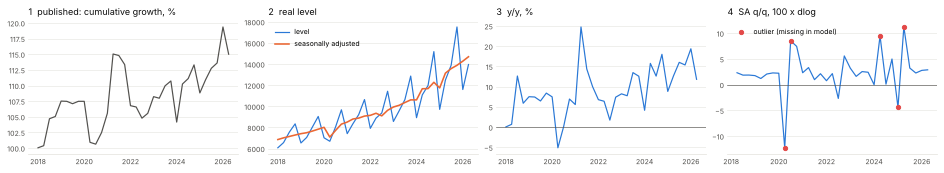

In [54]:
fig = report.figure(panels, inputs, 'gva_trade')
plt.show()

### `gva_accommodation`

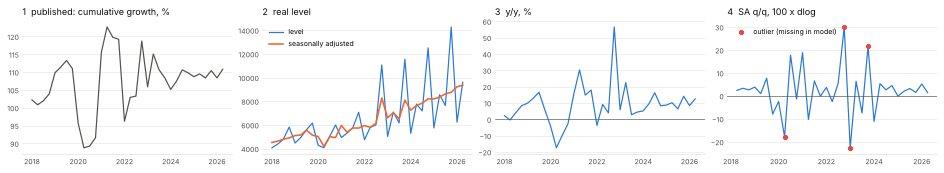

In [55]:
fig = report.figure(panels, inputs, 'gva_accommodation')
plt.show()

### `gva_transport_ict`

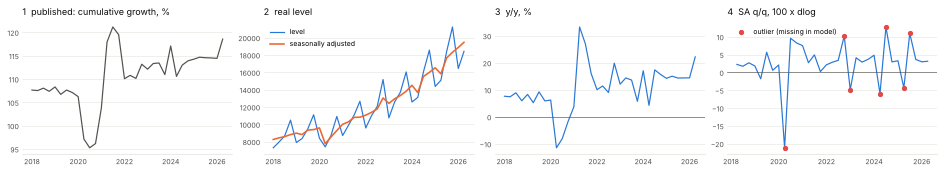

In [56]:
fig = report.figure(panels, inputs, 'gva_transport_ict')
plt.show()

### `gva_transport`

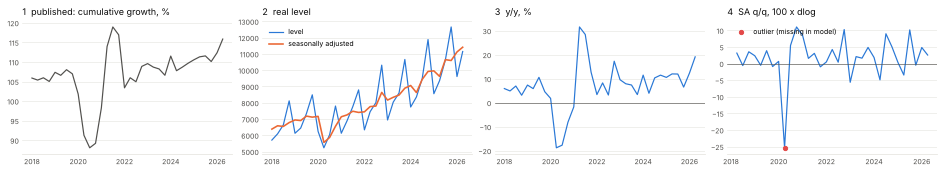

In [57]:
fig = report.figure(panels, inputs, 'gva_transport')
plt.show()

### `gva_ict`

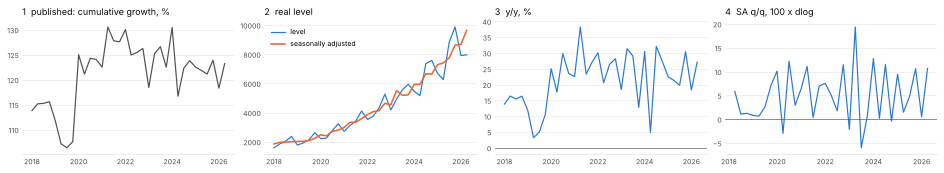

In [58]:
fig = report.figure(panels, inputs, 'gva_ict')
plt.show()

### `gva_other_services`

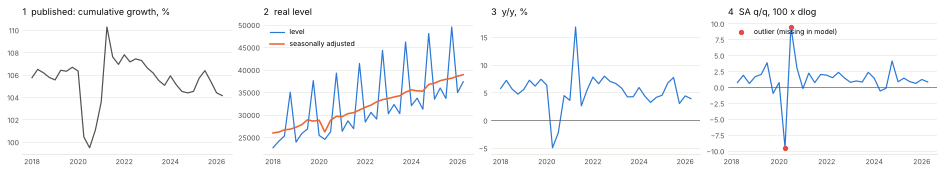

In [59]:
fig = report.figure(panels, inputs, 'gva_other_services')
plt.show()

### `net_taxes`

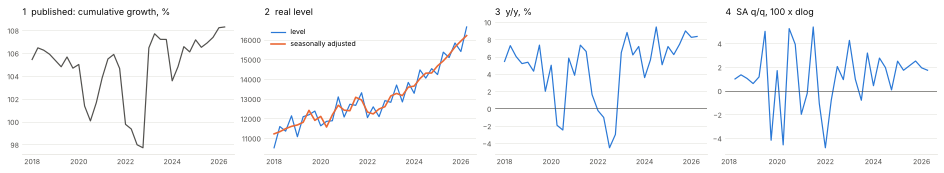

In [60]:
fig = report.figure(panels, inputs, 'net_taxes')
plt.show()

### `remittances_real`

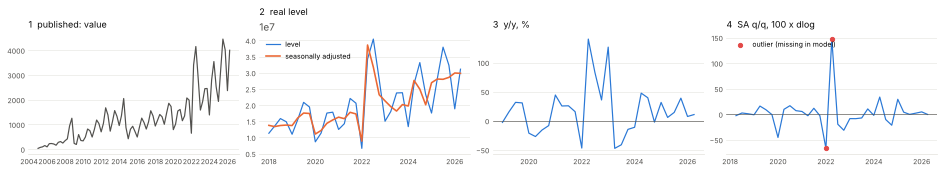

In [61]:
fig = report.figure(panels, inputs, 'remittances_real')
plt.show()

### `wages_real`

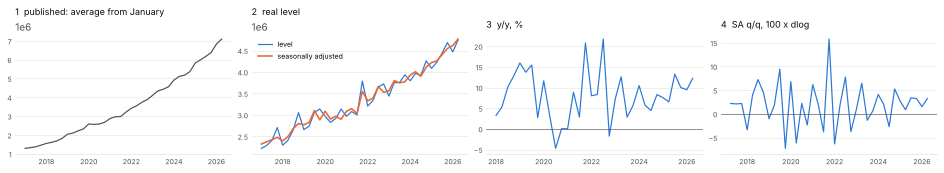

In [62]:
fig = report.figure(panels, inputs, 'wages_real')
plt.show()

### `income_real`

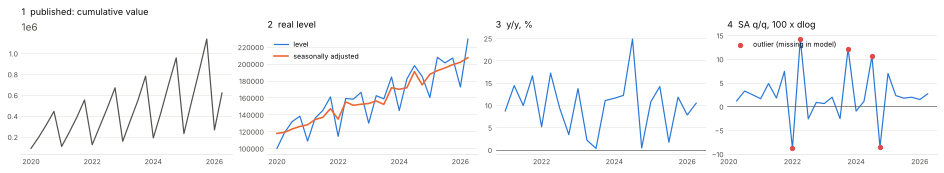

In [63]:
fig = report.figure(panels, inputs, 'income_real')
plt.show()

### `invest`

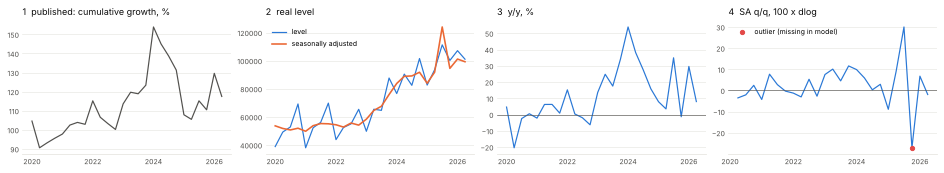

In [64]:
fig = report.figure(panels, inputs, 'invest')
plt.show()

### `invest_fdi_real`

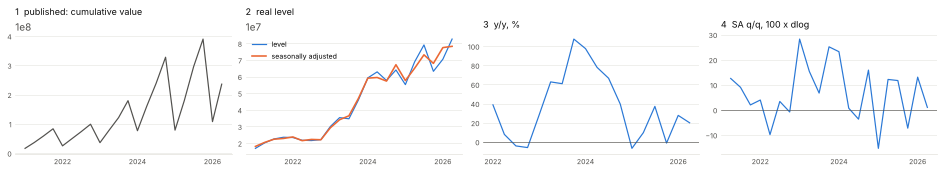

In [65]:
fig = report.figure(panels, inputs, 'invest_fdi_real')
plt.show()

### `agri_output`

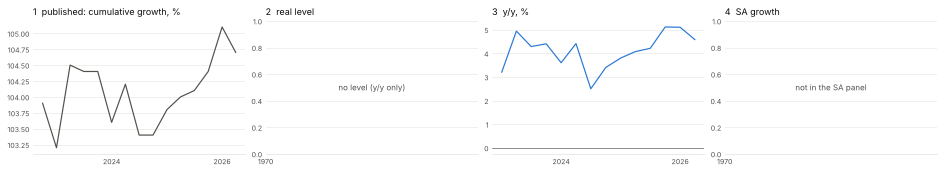

In [66]:
fig = report.figure(panels, inputs, 'agri_output')
plt.show()

### `freight`

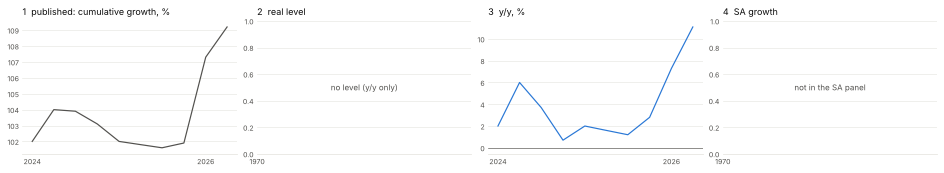

In [67]:
fig = report.figure(panels, inputs, 'freight')
plt.show()